# Phase 3 · Machine Learning (Q6)
**Hoàng Công Lý (`24120378`)**

**Với thông tin có trước khi gửi phiếu, mô hình dự đoán ý định nhận phiếu của người mới tốt hơn bao nhiêu so với cách luôn đoán “đồng ý nhận”?**

Cách luôn đoán “đồng ý nhận” là mô hình đối chứng (*baseline*), vì đây là câu trả lời phổ biến nhất trong tập huấn luyện. Để đánh giá khả năng dự đoán cho người mới, nhóm kiểm tra trên những hồ sơ chưa xuất hiện trong tập huấn luyện. Kết quả giúp ứng dụng quyết định tình huống nào nên được ưu tiên gửi phiếu.

**Mục lục:** 3.1 Bài toán & dữ liệu được phép dùng · 3.2 Tiền xử lý: chia train/test theo người & Pipeline · 3.3 Baseline, tinh chỉnh bằng CV trên train & kiểm tra rò rỉ · 3.4 Đánh giá test một lần & phân tích lỗi · 3.5 Diễn giải mô hình & trả lời Q6

## Phase 3.1 · Bài toán, prediction time & kiểm soát rò rỉ dữ liệu
- **Bài toán:** phân loại nhị phân `Y` (1 = chấp nhận coupon). Người dùng giả định là hệ thống gợi ý ưu đãi trên xe, chạy **trước khi** coupon được hiển thị.
- **Nguyên tắc prediction time:** chỉ dùng thông tin hệ thống đã biết tại thời điểm gợi ý; `Y` là nhãn nên không bao giờ nằm trong `X`.

| Nhóm | Đặc trưng (22) | Vì sao biết được trước lúc gợi ý |
| --- | --- | --- |
| Bối cảnh chuyến đi | `destination`, `passanger`, `weather`, `temperature`, `time`, `toCoupon_GEQ15min`, `toCoupon_GEQ25min`, `direction_same` | Ứng dụng dẫn đường biết điểm đến, giờ, thời tiết, vị trí quán; người đi cùng giả định khai báo được |
| Ưu đãi | `coupon`, `expiration` | Do chính hệ thống chọn trước khi gửi |
| Hồ sơ | `gender`, `age`, `maritalStatus`, `has_children`, `education`, `occupation`, `income` | Thông tin tài khoản người dùng |
| Thói quen | `Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50` | Khảo sát/lịch sử sẵn có (giả định người dùng đã khai báo — xem hạn chế cold-start) |

**Bị loại (4 cột):** `Y` (nhãn), `toCoupon_GEQ5min` (hằng số, không mang thông tin), `direction_opp` (= `1 − direction_same`, trùng thông tin), `car` (thiếu `99,15%` và có giá trị lạ — Phase 1).

In [1]:
import sys
from pathlib import Path

# Cho phép import gói coupon_project trong src/ dù mở notebook từ thư mục gốc hay notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, GroupShuffleSplit, StratifiedGroupKFold,
                                     StratifiedKFold, cross_val_score)

from coupon_project.data import RAW_CSV_PATH, load_raw_data, save_table
from coupon_project.features import build_respondent_id, matched_frequency
from coupon_project.modeling import (build_pipeline, cluster_bootstrap_metric,
                                     error_breakdown, probability_bins)
from coupon_project.plotting import save_figure, set_style

SEED = 42
set_style()

df = load_raw_data(RAW_CSV_PATH)  # đọc lại dữ liệu gốc, không phụ thuộc notebook khác
CONTEXT_COLS = ["destination", "passanger", "weather", "temperature", "time",
                "toCoupon_GEQ15min", "toCoupon_GEQ25min", "direction_same"]
COUPON_COLS = ["coupon", "expiration"]
PROFILE_COLS = ["gender", "age", "maritalStatus", "has_children", "education", "occupation",
                "income"]
HABIT_COLS = ["Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50"]
FEATURE_COLS = CONTEXT_COLS + COUPON_COLS + PROFILE_COLS + HABIT_COLS
EXCLUDED = {"Y", "toCoupon_GEQ5min", "direction_opp", "car"}  # nhãn, hằng, trùng, thiếu 99%

# Mỗi cột gốc thuộc đúng một nhóm: đặc trưng hoặc bị loại; nhãn Y không nằm trong X
assert "Y" not in FEATURE_COLS and set(FEATURE_COLS) | EXCLUDED == set(df.columns)
X, y = df[FEATURE_COLS], df["Y"]
print(f"X: {X.shape[0]:,} x {X.shape[1]} features | Y=1: {y.mean():.1%}")

X: 12,684 x 22 features | Y=1: 56.8%


## Phase 3.2 · Tiền xử lý: chia train/test theo người trả lời & Pipeline
1. **Không chia theo `time`** (chỉ là giờ trong ngày, không phải ngày tháng) và **không chia ngẫu nhiên theo dòng**: một người trả lời ~22 tình huống, nếu cùng người nằm ở cả train và test thì mô hình được "nhìn trước" người đó và điểm test bị thổi phồng.
2. Dựng `respondent_id` giống Q5 (các dòng có cùng toàn bộ hồ sơ + thói quen là một người) rồi chia **80/20 theo người** bằng `GroupShuffleSplit` (`random_state = 42`), kiểm tra không có người nào ở cả hai tập.
3. Toàn bộ tiền xử lý nằm **trong `Pipeline`** (`coupon_project.modeling.build_pipeline`): cột phân loại → `SimpleImputer(strategy="constant", fill_value="missing")` → `OneHotEncoder(handle_unknown="ignore")`; 4 cột 0/1 giữ nguyên. Vì Pipeline chỉ được `fit` trên dữ liệu train (của từng fold khi CV), mọi thông tin dùng để điền thiếu và mã hóa đều không lấy từ dữ liệu kiểm tra.

In [2]:
# respondent_id: các dòng có cùng toàn bộ hồ sơ + thói quen được coi là một người (như Q5)
respondent_id = build_respondent_id(df, PROFILE_COLS + ["car"] + HABIT_COLS)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups=respondent_id))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = respondent_id.iloc[train_idx], respondent_id.iloc[test_idx]

assert len(set(g_train) & set(g_test)) == 0  # không người nào nằm ở cả train và test
display(pd.DataFrame({
    "so_dong": [len(X_train), len(X_test)],
    "so_nguoi": [g_train.nunique(), g_test.nunique()],
    "ty_le_Y1_pct": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["train", "test"]).round(1))

BINARY_COLS = ["has_children", "toCoupon_GEQ15min", "toCoupon_GEQ25min", "direction_same"]
CAT_COLS = [c for c in FEATURE_COLS if c not in BINARY_COLS]  # kể cả temperature (3 mức)
print(f"{len(CAT_COLS)} cột phân loại -> SimpleImputer + OneHotEncoder; "
      f"{len(BINARY_COLS)} cột 0/1 giữ nguyên")

,so_dong,so_nguoi,ty_le_Y1_pct
train,10132,453,56.1
test,2552,114,59.9


18 cột phân loại -> SimpleImputer + OneHotEncoder; 4 cột 0/1 giữ nguyên


## Phase 3.3 · Baseline, tinh chỉnh bằng CV trên train & kiểm tra rò rỉ
- **Baseline tầm thường:** `DummyClassifier(strategy="most_frequent")` — luôn đoán lớp phổ biến nhất của train.
- **Hai mô hình:** `LogisticRegression` (tuyến tính, dễ diễn giải; tinh chỉnh độ mạnh điều chuẩn `C`) và `RandomForestClassifier` (300 cây, học được quan hệ phi tuyến/tương tác; tinh chỉnh `max_depth`, `min_samples_leaf`, `max_features`).
- **Tinh chỉnh:** `GridSearchCV` với `StratifiedGroupKFold(n_splits=5)` **chỉ trên tập train** — mỗi người nằm trọn trong một fold, tỷ lệ `Y` giữa các fold gần nhau.
- **Metric chính: ROC-AUC** — đo khả năng **xếp hạng** (không phụ thuộc ngưỡng 0,5), đúng với mục tiêu ưu tiên gửi coupon; kèm balanced accuracy (trung bình recall hai lớp). F1 chỉ để tham khảo vì baseline luôn đoán "nhận" đã có F1 cao khi lớp `Y = 1` chiếm ~57–60%.
- **Phiên bản:** kết quả ứng với `scikit-learn 1.8.0` (ghim trong `environment.yml`); các bản ≤ 1.7 chia fold `StratifiedGroupKFold(shuffle=True)` khác nên số liệu CV sẽ lệch.

In [3]:
MODELS = {
    "Dummy (đa số)": (DummyClassifier(strategy="most_frequent"), {}),
    "Logistic Regression": (LogisticRegression(max_iter=2000),
                            {"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 1.0]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
                      {"model__max_depth": [10, 20, None], "model__min_samples_leaf": [1, 5],
                       "model__max_features": ["sqrt", 0.2]}),
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)  # mỗi người trọn 1 fold
SCORING = ["roc_auc", "balanced_accuracy", "f1", "accuracy"]

# Kiểm tra 5 fold: không người nào nằm ở 2 fold và tỷ lệ Y của các fold gần nhau
fold_rows = []
for k, (tr, va) in enumerate(cv.split(X_train, y_train, groups=g_train), start=1):
    assert not set(g_train.iloc[tr]) & set(g_train.iloc[va])
    fold_rows.append({"fold": k, "so_nguoi": g_train.iloc[va].nunique(), "so_dong": len(va),
                      "ty_le_Y1_pct": y_train.iloc[va].mean() * 100})
display(pd.DataFrame(fold_rows).round(1))

# Tinh chỉnh bằng GridSearchCV CHỈ trên train; chọn tham số theo ROC-AUC
searches = {}
for name, (est, grid) in MODELS.items():
    gs = GridSearchCV(build_pipeline(est, CAT_COLS, BINARY_COLS), grid, scoring=SCORING,
                      refit="roc_auc", cv=cv, n_jobs=1)
    gs.fit(X_train, y_train, groups=g_train)
    searches[name] = gs
    print(f"{name}: best_params = {gs.best_params_}")

# Bảng CV: trung bình và độ lệch chuẩn qua 5 fold tại bộ tham số tốt nhất
cv_rows = {}
for name, gs in searches.items():
    best = gs.best_index_
    row = {f"{m}_mean": gs.cv_results_[f"mean_test_{m}"][best] for m in SCORING}
    row.update({f"{m}_std": gs.cv_results_[f"std_test_{m}"][best] for m in SCORING})
    cv_rows[name] = row
cv_table = pd.DataFrame(cv_rows).T
save_table(cv_table.reset_index(names="model"), "q6_cv_summary")
display(cv_table.round(4))

selected_name = cv_table["roc_auc_mean"].idxmax()
selected_model = searches[selected_name].best_estimator_
print(f"Mô hình chọn theo CV: {selected_name}")

,fold,so_nguoi,so_dong,ty_le_Y1_pct
0,1,91,2019,56.1
1,2,94,2030,56.3
2,3,90,2031,56.2
3,4,90,2030,55.9
4,5,88,2022,55.9


Dummy (đa số): best_params = {}


Logistic Regression: best_params = {'model__C': 0.01}


Random Forest: best_params = {'model__max_depth': 20, 'model__max_features': 0.2, 'model__min_samples_leaf': 5}


,roc_auc_mean,balanced_accuracy_mean,f1_mean,accuracy_mean,roc_auc_std,balanced_accuracy_std,f1_std,accuracy_std
Dummy (đa số),0.5000,0.5000,0.7186,0.5608,0.0000,0.0000,0.0011,0.0014
Logistic Regression,0.7218,0.6584,0.7259,0.6724,0.0111,0.0102,0.0098,0.0104
Random Forest,0.7670,0.7021,0.7592,0.7144,0.0090,0.0059,0.0087,0.0072


Mô hình chọn theo CV: Random Forest


In [4]:
# Kiểm tra rò rỉ: cùng tham số tốt nhất, nhưng chia fold theo DÒNG thay vì theo NGƯỜI
naive_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
leak_rows = {}
for name in ["Logistic Regression", "Random Forest"]:
    row_scores = cross_val_score(searches[name].best_estimator_, X_train, y_train,
                                 cv=naive_cv, scoring="roc_auc", n_jobs=1)
    leak_rows[name] = {"group_cv_auc": cv_table.loc[name, "roc_auc_mean"],
                       "row_cv_auc": row_scores.mean()}
leak_df = pd.DataFrame(leak_rows).T
leak_df["inflation"] = leak_df["row_cv_auc"] - leak_df["group_cv_auc"]
display(leak_df.round(4))
inflation_rf = leak_df.loc["Random Forest", "inflation"]
print(f"Random Forest: chia fold theo dòng làm ROC-AUC CV tăng giả tạo {inflation_rf:+.3f}")

,group_cv_auc,row_cv_auc,inflation
Logistic Regression,0.7218,0.7370,0.0152
Random Forest,0.7670,0.8101,0.0431


Random Forest: chia fold theo dòng làm ROC-AUC CV tăng giả tạo +0.043


#### Vì sao Random Forest tốt hơn Logistic Regression? *(chỉ dùng train + CV)*
Logistic Regression cộng dồn tác động riêng của từng cột sau One-Hot nên không tự học được **tương tác** kiểu "coupon `Bar` *và* người hay đi bar", còn cây quyết định tách liên tiếp theo nhiều cột nên học được. Để kiểm tra giả thuyết này mà **không chạm vào tập test**, thêm cho Logistic Regression một cột ghép `coupon × mức thói quen khớp coupon` rồi chấm lại bằng đúng CV ở trên. Cột ghép là biến đổi theo từng dòng (không học từ dữ liệu) nên không gây rò rỉ; mô hình này **không** dùng để chọn mô hình hay chấm test.

In [5]:
# Cột ghép: loại coupon + mức thói quen tương ứng (ví dụ "Bar|1~3"); ô thiếu ghi "missing"
habit_level = matched_frequency(X_train).fillna("missing").astype(str)
X_train_int = X_train.assign(coupon_x_habit=X_train["coupon"] + "|" + habit_level)
lr_int = GridSearchCV(build_pipeline(LogisticRegression(max_iter=2000),
                                     CAT_COLS + ["coupon_x_habit"], BINARY_COLS),
                      MODELS["Logistic Regression"][1], scoring="roc_auc", cv=cv, n_jobs=1)
lr_int.fit(X_train_int, y_train, groups=g_train)
print(f"CV ROC-AUC | LR gốc: {cv_table.loc['Logistic Regression', 'roc_auc_mean']:.3f} | "
      f"LR + coupon×thói quen: {lr_int.best_score_:.3f} | "
      f"Random Forest: {cv_table.loc['Random Forest', 'roc_auc_mean']:.3f}")

CV ROC-AUC | LR gốc: 0.722 | LR + coupon×thói quen: 0.748 | Random Forest: 0.767


## Phase 3.4 · Đánh giá test một lần & phân tích lỗi
- Mô hình đã được chốt bằng CV ở trên; đây là **lần duy nhất** dùng tập test. Cả 3 mô hình đều được chấm để lập bảng so sánh theo mẫu của đề, nhưng kết quả test không được dùng để đổi mô hình hay siêu tham số.
- CI 95% của điểm test: **bootstrap theo người** (rút lại `114` người test có hoàn lại, mỗi dòng nhận trọng số bằng số lần người đó được rút). Các mô hình dùng chung các lần rút nên CI của hiệu `RF − LR` là CI ghép cặp.
- Phân tích lỗi của mô hình được chọn ở ngưỡng `0,5`: **FP** = đoán nhận nhưng thật ra từ chối (gửi coupon gây phiền), **FN** = đoán từ chối nhưng thật ra muốn nhận (bỏ lỡ cơ hội). Xét theo `coupon`, `passanger`, `destination`, theo khoảng xác suất dự đoán và 6 ví dụ sai rút ngẫu nhiên.

In [6]:
# Đánh giá test MỘT lần; CI 95% bằng bootstrap theo người của tập test
test_proba, test_pred, test_rows, auc_draws = {}, {}, {}, {}
for name, gs in searches.items():
    p, yhat = gs.predict_proba(X_test)[:, 1], gs.predict(X_test)
    test_proba[name], test_pred[name] = p, yhat
    auc_draws[name] = cluster_bootstrap_metric(roc_auc_score, y_test, p, g_test, seed=SEED)
    bal_draws = cluster_bootstrap_metric(balanced_accuracy_score, y_test, yhat, g_test,
                                         seed=SEED)
    test_rows[name] = {
        "cv_roc_auc": cv_table.loc[name, "roc_auc_mean"],
        "test_roc_auc": roc_auc_score(y_test, p),
        "auc_ci_low": np.percentile(auc_draws[name], 2.5),
        "auc_ci_high": np.percentile(auc_draws[name], 97.5),
        "test_bal_acc": balanced_accuracy_score(y_test, yhat),
        "bal_ci_low": np.percentile(bal_draws, 2.5),
        "bal_ci_high": np.percentile(bal_draws, 97.5),
        "test_f1": f1_score(y_test, yhat),
        "test_acc": accuracy_score(y_test, yhat),
    }
test_table = pd.DataFrame(test_rows).T
save_table(test_table.reset_index(names="model"), "q6_test_metrics")
display(test_table.round(3))

# Bảng kết quả cuối theo mẫu đề: CV (mean ± std trên 5 fold) + 3 metric test
cv_text = [f"{cv_table.loc[m, 'roc_auc_mean']:.3f} ± {cv_table.loc[m, 'roc_auc_std']:.3f}"
           for m in MODELS]
final_table = pd.DataFrame({
    "CV ROC-AUC (mean ± std)": cv_text,
    "Test F1": test_table["test_f1"].round(3),
    "Test ROC-AUC": test_table["test_roc_auc"].round(3),
    "Test balanced accuracy": test_table["test_bal_acc"].round(3),
}, index=pd.Index(list(MODELS), name="Model"))
save_table(final_table.reset_index(), "q6_final_table")
display(final_table)

rf_minus_lr = (test_table.loc["Random Forest", "test_roc_auc"]
               - test_table.loc["Logistic Regression", "test_roc_auc"])
gap_draws = auc_draws["Random Forest"] - auc_draws["Logistic Regression"]
print(f"RF - LogReg test ROC-AUC = {rf_minus_lr:.3f} "
      f"(95% CI: {np.percentile(gap_draws, 2.5):.3f} to {np.percentile(gap_draws, 97.5):.3f})")

,cv_roc_auc,test_roc_auc,auc_ci_low,auc_ci_high,test_bal_acc,bal_ci_low,bal_ci_high,test_f1,test_acc
Dummy (đa số),0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.749,0.599
Logistic Regression,0.722,0.726,0.700,0.753,0.660,0.638,0.682,0.744,0.682
Random Forest,0.767,0.781,0.755,0.807,0.706,0.682,0.732,0.775,0.724


,CV ROC-AUC (mean ± std),Test F1,Test ROC-AUC,Test balanced accuracy
Model,,,,
Dummy (đa số),0.500 ± 0.000,0.749,0.500,0.500
Logistic Regression,0.722 ± 0.011,0.744,0.726,0.660
Random Forest,0.767 ± 0.009,0.775,0.781,0.706


RF - LogReg test ROC-AUC = 0.055 (95% CI: 0.037 to 0.074)


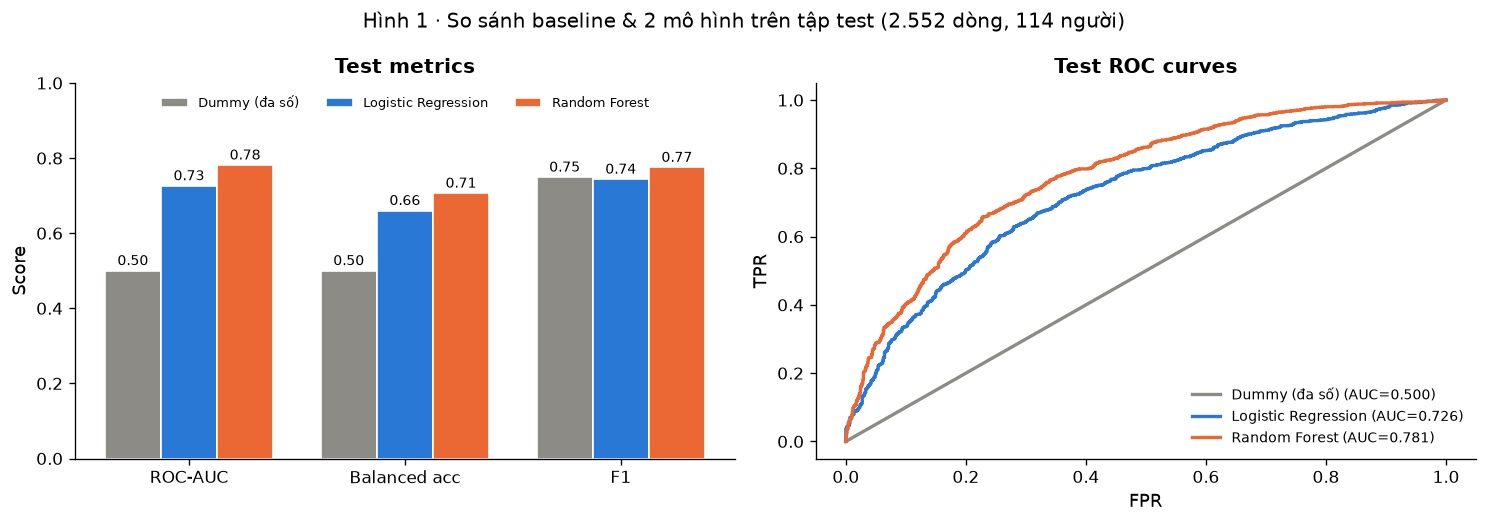

In [7]:
# Hình 1: so sánh 3 metric test và đường ROC
COLORS = {"Dummy (đa số)": "#8c8b86", "Logistic Regression": "#2a78d6",
          "Random Forest": "#eb6834"}
METRICS = {"test_roc_auc": "ROC-AUC", "test_bal_acc": "Balanced acc", "test_f1": "F1"}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
x = np.arange(3)
for k, name in enumerate(MODELS):
    vals = test_table.loc[name, list(METRICS)].to_numpy(float)
    pos = x + (k - 1) * 0.26
    axes[0].bar(pos, vals, width=0.26, color=COLORS[name], edgecolor="white", label=name)
    for xp, v in zip(pos, vals):
        axes[0].text(xp, v + 0.015, f"{v:.2f}", ha="center", fontsize=8.5)
axes[0].set_xticks(x, METRICS.values())
axes[0].set(ylim=(0, 1), ylabel="Score", title="Test metrics")
axes[0].legend(frameon=False, loc="upper center", ncol=3, fontsize=8)

for name in MODELS:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    auc_label = f"{name} (AUC={test_table.loc[name, 'test_roc_auc']:.3f})"
    axes[1].plot(fpr, tpr, color=COLORS[name], linewidth=2, label=auc_label)
axes[1].set(xlabel="FPR", ylabel="TPR", title="Test ROC curves")
axes[1].legend(frameon=False, loc="lower right", fontsize=8.5)
n_test_text = f"{len(X_test):,}".replace(",", ".")  # viết số kiểu Việt Nam: 2.552
fig.suptitle(f"Hình 1 · So sánh baseline & 2 mô hình trên tập test "
             f"({n_test_text} dòng, {g_test.nunique()} người)")
fig.tight_layout()
save_figure(fig, "q6_fig1_model_comparison")
plt.show()

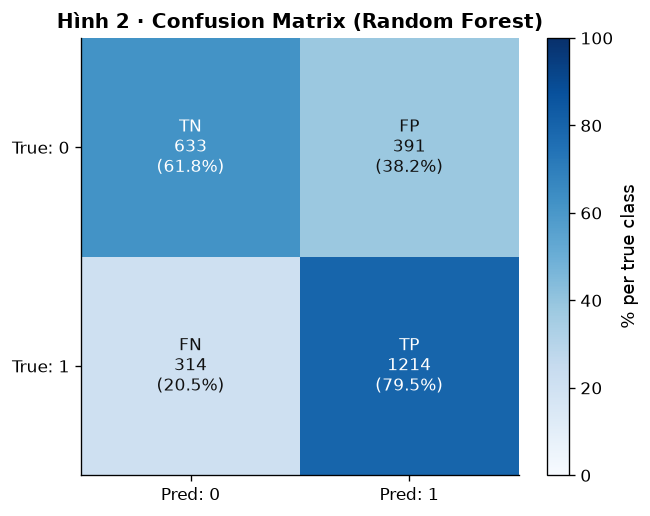

In [8]:
# Hình 2: ma trận nhầm lẫn của mô hình đã chọn (ngưỡng 0,5)
sel_pred, sel_prob = test_pred[selected_name], test_proba[selected_name]
cm = confusion_matrix(y_test, sel_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100  # % theo từng lớp thật

fig, ax = plt.subplots(figsize=(5.6, 4.4))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
names_cm = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        text_color = "white" if cm_pct[i, j] >= 50 else "#111"
        ax.text(j, i, f"{names_cm[i][j]}\n{cm[i, j]}\n({cm_pct[i, j]:.1f}%)",
                ha="center", va="center", color=text_color)
ax.set_xticks([0, 1], ["Pred: 0", "Pred: 1"])
ax.set_yticks([0, 1], ["True: 0", "True: 1"])
ax.set_title(f"Hình 2 · Confusion Matrix ({selected_name})")
fig.colorbar(im, ax=ax, label="% per true class")
fig.tight_layout()
save_figure(fig, "q6_fig2_confusion_matrix")
plt.show()

,n,true_rate,acc,FPR,FNR
coupon,,,,,
Restaurant(20-50),302,0.447,0.656,22.75,48.89
Bar,390,0.474,0.636,22.44,51.89
Coffee House,821,0.498,0.728,31.80,22.49
Restaurant(<20),562,0.760,0.769,60.00,11.48
Carry out & Take away,477,0.780,0.778,90.48,2.96


,n,true_rate,acc,FPR,FNR
passanger,,,,,
Alone,1484,0.553,0.703,31.48,28.29
Partner,193,0.565,0.715,51.19,11.01
Kid(s),198,0.586,0.747,19.51,29.31
Friend(s),677,0.713,0.765,63.40,7.45


,n,true_rate,acc,FPR,FNR
destination,,,,,
Work,649,0.505,0.700,29.28,30.79
Home,642,0.542,0.673,28.23,36.49
No Urgent Place,1261,0.676,0.762,52.32,10.09


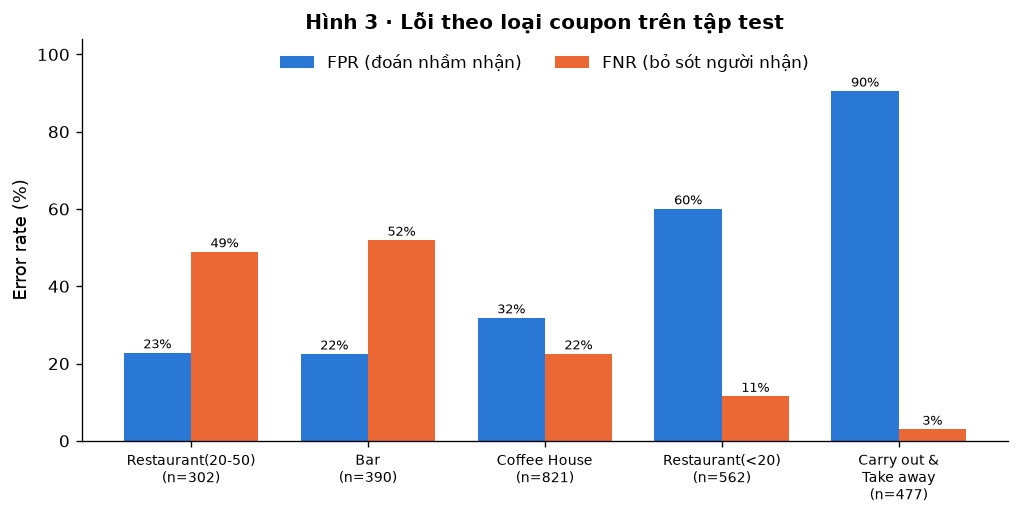

In [9]:
# Bảng lỗi theo 3 nhóm và Hình 3: FPR/FNR theo loại coupon
err_tables = {}
for col in ["coupon", "passanger", "destination"]:
    err_tables[col] = error_breakdown(X_test, y_test, sel_pred, col)
    save_table(err_tables[col].reset_index(), f"q6_errors_by_{col}")
    display(err_tables[col])

by_c = err_tables["coupon"]
fig, ax = plt.subplots(figsize=(8.6, 4.4))
xc = np.arange(len(by_c))
ax.bar(xc - 0.19, by_c["FPR"], width=0.38, color="#2a78d6", label="FPR (đoán nhầm nhận)")
ax.bar(xc + 0.19, by_c["FNR"], width=0.38, color="#eb6834", label="FNR (bỏ sót người nhận)")
for xp, fpv, fnv in zip(xc, by_c["FPR"], by_c["FNR"]):
    ax.text(xp - 0.19, fpv + 1.2, f"{fpv:.0f}%", ha="center", fontsize=8)
    ax.text(xp + 0.19, fnv + 1.2, f"{fnv:.0f}%", ha="center", fontsize=8)
# Python 3.11 không cho dấu \ bên trong {...} của f-string, nên tạo nhãn trục trước
xlabels = [c.replace(" & ", " &\n") + f"\n(n={n})" for c, n in zip(by_c.index, by_c["n"])]
ax.set_xticks(xc, xlabels, fontsize=8.5)
ax.set(ylim=(0, 104), ylabel="Error rate (%)",
       title="Hình 3 · Lỗi theo loại coupon trên tập test")
ax.legend(frameon=False, loc="upper center", ncol=2)
fig.tight_layout()
save_figure(fig, "q6_fig3_errors_by_coupon")
plt.show()

In [10]:
# Lỗi theo khoảng xác suất dự đoán
display(probability_bins(y_test, sel_pred, sel_prob))

# Ví dụ sai minh họa: rút ngẫu nhiên (random_state cố định, không chọn tay) 3 FP và 3 FN
view_cols = ["coupon", "expiration", "destination", "passanger", "time", "CoffeeHouse", "Bar",
             "CarryAway"]
test_view = X_test[view_cols].copy()
test_view["y_true"], test_view["y_pred"] = y_test.to_numpy(), sel_pred
test_view["p_nhan"] = sel_prob.round(3)
is_fp = (test_view["y_true"] == 0) & (test_view["y_pred"] == 1)
is_fn = (test_view["y_true"] == 1) & (test_view["y_pred"] == 0)
fp_examples = test_view[is_fp].sample(3, random_state=SEED)
fn_examples = test_view[is_fn].sample(3, random_state=SEED)
print(f"Tổng lỗi: {cm[0, 1] + cm[1, 0]} (FP = {cm[0, 1]}, FN = {cm[1, 0]})")
display(pd.concat([fp_examples.assign(loai_loi="FP"), fn_examples.assign(loai_loi="FN")]))

,n,mean_p,true_y,acc
p_bin,,,,
"(-0.001, 0.3]",422,0.208,0.190,0.810
"(0.3, 0.4]",251,0.354,0.410,0.590
"(0.4, 0.5]",274,0.455,0.478,0.522
"(0.5, 0.6]",340,0.552,0.571,0.571
"(0.6, 0.7]",441,0.650,0.732,0.732
"(0.7, 1.0]",824,0.797,0.846,0.846


Tổng lỗi: 705 (FP = 391, FN = 314)


,coupon,expiration,destination,passanger,time,CoffeeHouse,Bar,CarryAway,y_true,y_pred,p_nhan,loai_loi
207,Restaurant(20-50),1d,Home,Alone,6PM,never,less1,gt8,0,1,0.579,FP
1564,Carry out & Take away,2h,Work,Alone,7AM,less1,less1,1~3,0,1,0.684,FP
1484,Restaurant(<20),2h,No Urgent Place,Friend(s),6PM,1~3,never,less1,0,1,0.824,FP
5381,Restaurant(<20),2h,Home,Alone,10PM,1~3,4~8,1~3,1,0,0.437,FN
1654,Coffee House,2h,Work,Alone,7AM,4~8,1~3,1~3,1,0,0.371,FN
9368,Restaurant(20-50),1d,Home,Alone,6PM,never,never,never,1,0,0.486,FN


## Phase 3.5 · Diễn giải mô hình & trả lời Q6
**Permutation importance** trên tập test: xáo trộn ngẫu nhiên từng cột gốc (10 lần) rồi đo ROC-AUC giảm bao nhiêu. Vì xáo trộn cột *gốc* trước khi qua Pipeline, mỗi đặc trưng được đánh giá trọn vẹn (không bị chia nhỏ theo các cột One-Hot). Cách này không dùng để chọn mô hình nên không vi phạm nguyên tắc "test một lần".

,mean_drop_auc,std
coupon,0.1573,0.0092
CoffeeHouse,0.0569,0.0039
expiration,0.0495,0.0046
Bar,0.0168,0.0025
destination,0.0148,0.0022
time,0.0091,0.0021
passanger,0.0061,0.0016
toCoupon_GEQ15min,0.0027,0.0013
temperature,0.0019,0.0013
CarryAway,0.0015,0.0007


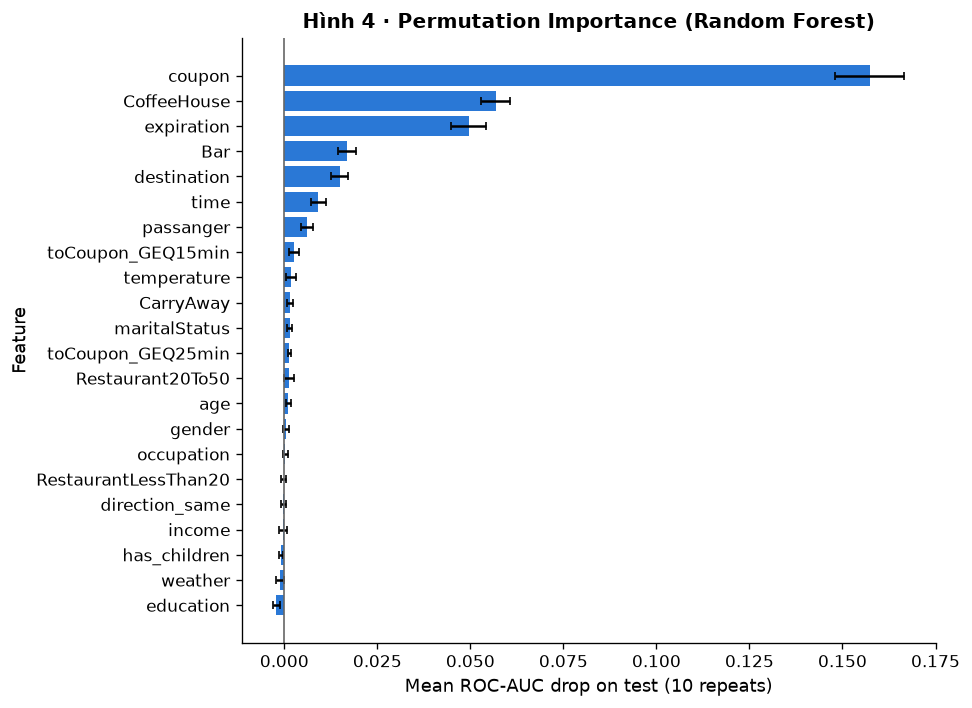

In [11]:
imp = permutation_importance(selected_model, X_test, y_test, scoring="roc_auc", n_repeats=10,
                             random_state=SEED, n_jobs=1)
imp_df = (pd.DataFrame({"mean_drop_auc": imp.importances_mean, "std": imp.importances_std},
                       index=FEATURE_COLS)
          .sort_values("mean_drop_auc", ascending=False))
save_table(imp_df.reset_index(names="feature"), "q6_permutation_importance")
display(imp_df.round(4))  # đủ 22 đặc trưng, kể cả nhóm nhân khẩu học

plot_imp = imp_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.2, 6.0))
ax.barh(plot_imp.index, plot_imp["mean_drop_auc"], xerr=plot_imp["std"], color="#2a78d6",
        capsize=2.5)
ax.axvline(0, color="#666", linewidth=1)
ax.set(xlabel="Mean ROC-AUC drop on test (10 repeats)", ylabel="Feature",
       title=f"Hình 4 · Permutation Importance ({selected_name})")
fig.tight_layout()
save_figure(fig, "q6_fig4_permutation_importance")
plt.show()

#### Kết quả có phụ thuộc vào một lần chia train/test may mắn không?
Tập test chỉ có `114` người nên điểm test dao động theo cách chia. Lặp lại phép chia 80/20 theo người với **50 seed khác nhau** (có cả seed 42), **giữ nguyên** cấu hình đã chọn bằng CV ở trên (không tinh chỉnh lại). Phân tích này chỉ để đo độ ổn định, **không** dùng để chọn hay sửa mô hình.

In [12]:
stab_rows = []
for s in range(50):
    split_s = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=s)
    tr, te = next(split_s.split(X, y, groups=respondent_id))
    row = {"seed": s, "ty_le_Y1_test_pct": y.iloc[te].mean() * 100}
    for name in ["Logistic Regression", "Random Forest"]:
        model = clone(searches[name].best_estimator_).fit(X.iloc[tr], y.iloc[tr])
        row[name] = roc_auc_score(y.iloc[te], model.predict_proba(X.iloc[te])[:, 1])
    stab_rows.append(row)
stability = pd.DataFrame(stab_rows)
stability["RF - LR"] = stability["Random Forest"] - stability["Logistic Regression"]
save_table(stability, "q6_split_stability")

summary_cols = ["Logistic Regression", "Random Forest", "RF - LR", "ty_le_Y1_test_pct"]
display(stability[summary_cols].describe().loc[["mean", "std", "min", "max"]].round(3))
print(f"Seed 42 (bản chính): RF test ROC-AUC = {test_table.loc['Random Forest', 'test_roc_auc']:.3f}"
      f", tỷ lệ Y=1 của tập test = {y_test.mean() * 100:.1f}% | "
      f"RF > LR ở {(stability['RF - LR'] > 0).sum()}/{len(stability)} cách chia")

,Logistic Regression,Random Forest,RF - LR,ty_le_Y1_test_pct
mean,0.724,0.774,0.049,56.772
std,0.012,0.012,0.008,1.994
min,0.702,0.752,0.034,50.846
max,0.748,0.801,0.067,60.519


Seed 42 (bản chính): RF test ROC-AUC = 0.781, tỷ lệ Y=1 của tập test = 59.9% | RF > LR ở 50/50 cách chia


### Trả lời Q6 và hạn chế

**Trên những hồ sơ chưa xuất hiện khi huấn luyện, Random Forest xếp hạng các tình huống người tham gia đồng ý nhận phiếu tốt hơn mô hình đối chứng.** Mô hình đạt **ROC-AUC 0,781**, so với **0,500** khi luôn đoán “đồng ý nhận”. Điểm ROC-AUC càng cao, mô hình càng có xu hướng xếp một tình huống được chấp nhận lên trên một tình huống bị từ chối.

- **Dự đoán đúng bao nhiêu?** Trên tập kiểm tra gồm 114 hồ sơ, Random Forest dự đoán đúng **72,4%** số tình huống, so với **59,9%** của mô hình đối chứng. Khi tính tỷ lệ dự đoán đúng riêng cho nhóm nhận và nhóm từ chối rồi lấy trung bình, điểm lần lượt là **0,706** và **0,500**. Khoảng tin cậy 95% của ROC-AUC cho Random Forest là 0,755 đến 0,807.
- **Kết quả có phụ thuộc vào cách chia dữ liệu?** Trong cả 50 lần chia lại theo hồ sơ người trả lời, Random Forest đều có ROC-AUC cao hơn hồi quy logistic. ROC-AUC trung bình của Random Forest là **0,774**, gần với kết quả của lần kiểm tra chính. Nếu chia theo từng dòng, câu trả lời của cùng một người có thể nằm ở cả hai tập và điểm đánh giá chéo tăng thêm 0,043.
- **Mô hình dựa vào thông tin nào?** Đổi ngẫu nhiên loại phiếu giữa các dòng làm điểm xếp hạng giảm nhiều nhất, tiếp theo là thói quen đi cà phê và thời hạn phiếu. Với hồi quy logistic, bổ sung biến kết hợp loại phiếu với thói quen tương ứng cũng giúp ROC-AUC khi đánh giá chéo tăng từ 0,722 lên 0,748.
- **Mô hình hay sai ở đâu?** Với đồ ăn mang đi, trong số những tình huống người trả lời từ chối, **90,5%** bị đoán là sẽ nhận. Với quán bar, trong số những tình huống người trả lời đồng ý nhận, mô hình bỏ sót **51,9%**. Hai tỷ lệ này cho thấy cần xem riêng từng loại dịch vụ khi chọn ngưỡng gửi phiếu.
- **Có thể dùng kết quả như thế nào?** Có thể thử dùng điểm dự đoán để xếp thứ tự ưu tiên gửi phiếu. Khảo sát chỉ ghi ý định nhận phiếu, nên cần kiểm tra thêm bằng lượt sử dụng thực tế. Kết quả cũng phụ thuộc vào thông tin thói quen đã có và độ chính xác của mã người trả lời được suy ra từ hồ sơ.